# Five-Class Image Classification: ResNet50 vs DenseNet121

Google Colab notebook using the `dataset.zip` in Google Drive.

**Important dataset check:** the uploaded ZIP was inspected. Its folders are `cat`, `cow`, `dog`, `lamb`, and `zebra` (100 images each). The folder is named **`lamb`**, not `lamp`. This notebook uses the actual folder name from the ZIP.

Workflow: Drive mount → ZIP extraction → data inspection → stratified 70/15/15 split → train ResNet50 and DenseNet121 → test metrics and confusion matrices → compare → save weights and results to Drive.

## 1. Install/import libraries

In [ ]:
# Colab usually already has PyTorch, torchvision, sklearn, pandas and matplotlib.
import os, glob, zipfile, copy, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

print('Imports complete')
print('PyTorch:', torch.__version__)
print('Torchvision:', __import__('torchvision').__version__)

Imports complete
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130


## 2. Set seed and check GPU

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU is not enabled. In Colab choose Runtime > Change runtime type > T4 GPU.')

Device: cuda
GPU: Tesla T4


## 3. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Locate `dataset.zip`

If the ZIP is in a shared Drive folder, add a shortcut to **My Drive** first (Drive → right-click `dataset.zip` → Organize → Add shortcut → My Drive). The search below looks recursively in My Drive. If several files named `dataset.zip` appear, set `ZIP_PATH` manually to the correct printed path.

In [ ]:
# Automatic search
zip_candidates = glob.glob('/content/drive/MyDrive/**/dataset.zip', recursive=True)
print('Matching dataset.zip files:')
for i, p in enumerate(zip_candidates):
    print(i, p)

# If needed, manually enter the exact path, e.g.:
# ZIP_PATH = '/content/drive/MyDrive/Dataset/dataset.zip'
ZIP_PATH = zip_candidates[0] if len(zip_candidates) == 1 else None

if ZIP_PATH is None:
    raise FileNotFoundError(
        'Could not uniquely identify dataset.zip. Set ZIP_PATH manually using one of the paths printed above.'
    )
print('Selected ZIP:', ZIP_PATH)

Matching dataset.zip files:
0 /content/drive/MyDrive/Dataset/dataset.zip
Selected ZIP: /content/drive/MyDrive/Dataset/dataset.zip


## 5. Extract ZIP

In [ ]:
EXTRACT_ROOT = '/content/image_dataset'
os.makedirs(EXTRACT_ROOT, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_ROOT)

print('Extracted to:', EXTRACT_ROOT)

Extracted to: /content/image_dataset


## 6. Find the class-folder directory and verify labels

In [ ]:
# Actual class folder names found in the uploaded ZIP:
EXPECTED_CLASSES = {'cat', 'cow', 'dog', 'lamb', 'zebra'}

candidate_dirs = []
for root, dirs, files in os.walk(EXTRACT_ROOT):
    lower_dirs = {d.lower() for d in dirs}
    if EXPECTED_CLASSES.issubset(lower_dirs):
        candidate_dirs.append(root)

if not candidate_dirs:
    raise FileNotFoundError(
        f'Could not find folders {sorted(EXPECTED_CLASSES)}. Check the ZIP structure.'
    )

DATA_DIR = min(candidate_dirs, key=lambda p: len(Path(p).parts))
print('DATA_DIR:', DATA_DIR)
print('Class folders:', sorted([p.name for p in Path(DATA_DIR).iterdir() if p.is_dir()]))

# Validate image counts/extensions and inspect dataset
valid_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
for cls in sorted(EXPECTED_CLASSES):
    folder = Path(DATA_DIR) / cls
    files = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in valid_ext]
    print(f'{cls}: {len(files)} images')

DATA_DIR: /content/image_dataset/dataset
Class folders: ['cat', 'cow', 'dog', 'lamb', 'zebra']
cat: 100 images
cow: 100 images
dog: 100 images
lamb: 213 images
zebra: 100 images


## 7. Load images with ImageFolder

In [ ]:
base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
num_classes = len(class_names)
labels = np.array(base_dataset.targets)

print('Class order used by model:', class_names)
print('Number of classes:', num_classes)
print('Total images:', len(base_dataset))
assert num_classes == 5, f'Expected 5 classes, found {num_classes}'

Class order used by model: ['cat', 'cow', 'dog', 'lamb', 'zebra']
Number of classes: 5
Total images: 613


## 8. Class distribution chart

,Class,Image count
0,cat,100
1,cow,100
2,dog,100
3,lamb,213
4,zebra,100


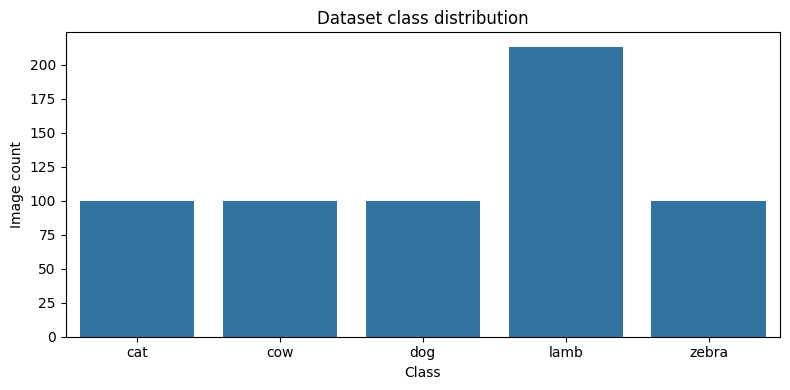

In [ ]:
counts = pd.Series(labels).value_counts().sort_index()
distribution = pd.DataFrame({'Class': class_names, 'Image count': counts.values})
display(distribution)

plt.figure(figsize=(8, 4))
sns.barplot(data=distribution, x='Class', y='Image count')
plt.title('Dataset class distribution')
plt.tight_layout()
plt.show()

## 9. Image transforms

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2

# Augmentation is applied only to training images.
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])
print('Transforms ready')

Transforms ready


## 10. Stratified train/validation/test split (70/15/15)

In [ ]:
all_indices = np.arange(len(base_dataset))
train_idx, temp_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=labels[temp_idx]
)

print(f'Train: {len(train_idx)} ({len(train_idx)/len(all_indices):.1%})')
print(f'Validation: {len(val_idx)} ({len(val_idx)/len(all_indices):.1%})')
print(f'Test: {len(test_idx)} ({len(test_idx)/len(all_indices):.1%})')

Train: 429 (70.0%)
Validation: 92 (15.0%)
Test: 92 (15.0%)


## 11. Create datasets and DataLoaders

In [ ]:
train_all = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_all = datasets.ImageFolder(DATA_DIR, transform=eval_transform)

train_dataset = Subset(train_all, train_idx)
val_dataset = Subset(eval_all, val_idx)
test_dataset = Subset(eval_all, test_idx)

pin = DEVICE.type == 'cuda'
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

print('Train batches:', len(train_loader))
print('Validation batches:', len(val_loader))
print('Test batches:', len(test_loader))

Train batches: 27
Validation batches: 6
Test batches: 6


## 12. Display sample training images

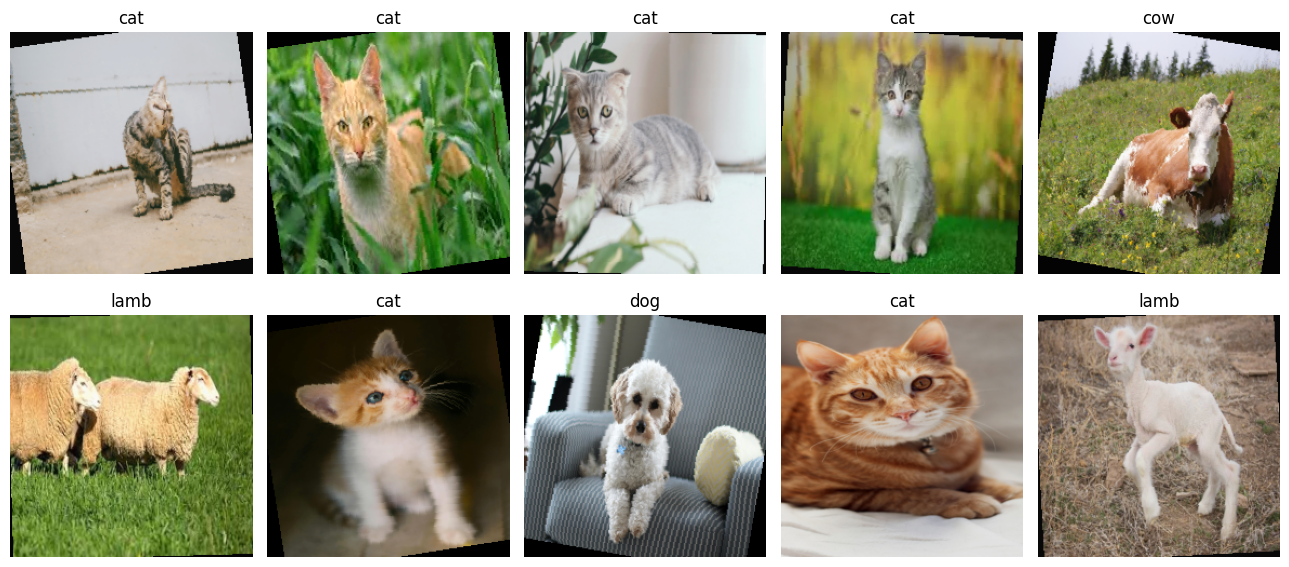

In [ ]:
def show_samples(dataset, names, n=10):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    chosen = np.random.choice(len(dataset), min(n, len(dataset)), replace=False)
    plt.figure(figsize=(13, 6))
    for i, idx in enumerate(chosen):
        image, label = dataset[idx]
        image = (image * std + mean).clamp(0, 1)
        plt.subplot(2, 5, i + 1)
        plt.imshow(image.permute(1, 2, 0).numpy())
        plt.title(names[label])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_samples(train_dataset, class_names)

## 13. Model builder: ResNet50 / DenseNet121

In [ ]:
def build_model(model_name, num_classes):
    if model_name == 'ResNet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == 'DenseNet121':
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    else:
        raise ValueError('model_name must be ResNet50 or DenseNet121')
    return model.to(DEVICE)

print('Model builder ready')

Model builder ready


## 14. Training and validation functions

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, targets)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == targets).sum().item()
        total += targets.size(0)

    return total_loss / total, correct / total


def train_model(model_name, epochs=15, learning_rate=1e-4):
    model = build_model(model_name, num_classes)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                  weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2
    )
    history = {'train_loss': [], 'val_loss': [],
               'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_state = copy.deepcopy(model.state_dict())
    checkpoint = f'/content/best_{model_name.lower()}.pth'

    for epoch in range(epochs):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, checkpoint)

        print(f'{model_name} | Epoch {epoch+1}/{epochs} | '
              f'train loss={train_loss:.4f}, acc={train_acc:.4f} | '
              f'val loss={val_loss:.4f}, acc={val_acc:.4f} | '
              f'{time.time()-start:.1f}s')

    model.load_state_dict(best_state)
    return model, history, checkpoint

## 15. Train ResNet50

In [ ]:
EPOCHS = 15  # You can increase this after confirming the first run works.
resnet50, resnet_history, resnet_checkpoint = train_model(
    'ResNet50', epochs=EPOCHS, learning_rate=1e-4
)
print('ResNet50 training finished. Best checkpoint:', resnet_checkpoint)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


ResNet50 | Epoch 1/15 | train loss=1.1962, acc=0.6760 | val loss=0.4694, acc=0.9565 | 41.7s
ResNet50 | Epoch 2/15 | train loss=0.3124, acc=0.9697 | val loss=0.1235, acc=0.9674 | 42.5s
ResNet50 | Epoch 3/15 | train loss=0.0870, acc=0.9883 | val loss=0.1018, acc=0.9674 | 49.0s
ResNet50 | Epoch 4/15 | train loss=0.0585, acc=0.9907 | val loss=0.0658, acc=0.9891 | 43.6s
ResNet50 | Epoch 5/15 | train loss=0.0256, acc=0.9953 | val loss=0.0545, acc=0.9783 | 42.5s
ResNet50 | Epoch 6/15 | train loss=0.0344, acc=0.9907 | val loss=0.0738, acc=0.9674 | 43.5s
ResNet50 | Epoch 7/15 | train loss=0.0373, acc=0.9930 | val loss=0.1959, acc=0.9457 | 43.4s
ResNet50 | Epoch 8/15 | train loss=0.0274, acc=0.9977 | val loss=0.0411, acc=0.9891 | 43.8s
ResNet50 | Epoch 9/15 | train loss=0.0213, acc=0.9930 | val loss=0.0822, acc=0.9674 | 41.7s
ResNet50 | Epoch 10/15 | train loss=0.0108, acc=1.0000 | val loss=0.0843, acc=0.9783 | 40.2s
ResNet50 | Epoch 11/15 | train loss=0.0692, acc=0.9790 | val loss=0.0979, acc=0

## 16. Train DenseNet121

In [ ]:
densenet121, dense_history, dense_checkpoint = train_model(
    'DenseNet121', epochs=EPOCHS, learning_rate=1e-4
)
print('DenseNet121 training finished. Best checkpoint:', dense_checkpoint)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s]


DenseNet121 | Epoch 1/15 | train loss=0.8082, acc=0.7855 | val loss=0.2953, acc=0.9130 | 41.8s
DenseNet121 | Epoch 2/15 | train loss=0.1646, acc=0.9814 | val loss=0.1708, acc=0.9348 | 41.8s
DenseNet121 | Epoch 3/15 | train loss=0.1089, acc=0.9837 | val loss=0.1437, acc=0.9565 | 42.0s
DenseNet121 | Epoch 4/15 | train loss=0.0573, acc=0.9953 | val loss=0.1425, acc=0.9348 | 42.6s
DenseNet121 | Epoch 5/15 | train loss=0.0412, acc=0.9977 | val loss=0.1375, acc=0.9565 | 42.9s
DenseNet121 | Epoch 6/15 | train loss=0.0301, acc=0.9977 | val loss=0.1348, acc=0.9565 | 40.8s
DenseNet121 | Epoch 7/15 | train loss=0.0254, acc=1.0000 | val loss=0.1360, acc=0.9565 | 40.9s
DenseNet121 | Epoch 8/15 | train loss=0.0296, acc=0.9930 | val loss=0.1448, acc=0.9565 | 41.7s
DenseNet121 | Epoch 9/15 | train loss=0.0393, acc=0.9930 | val loss=0.1846, acc=0.9239 | 42.2s
DenseNet121 | Epoch 10/15 | train loss=0.0274, acc=0.9977 | val loss=0.1499, acc=0.9348 | 42.2s
DenseNet121 | Epoch 11/15 | train loss=0.0268, ac

## 17. Plot training curves

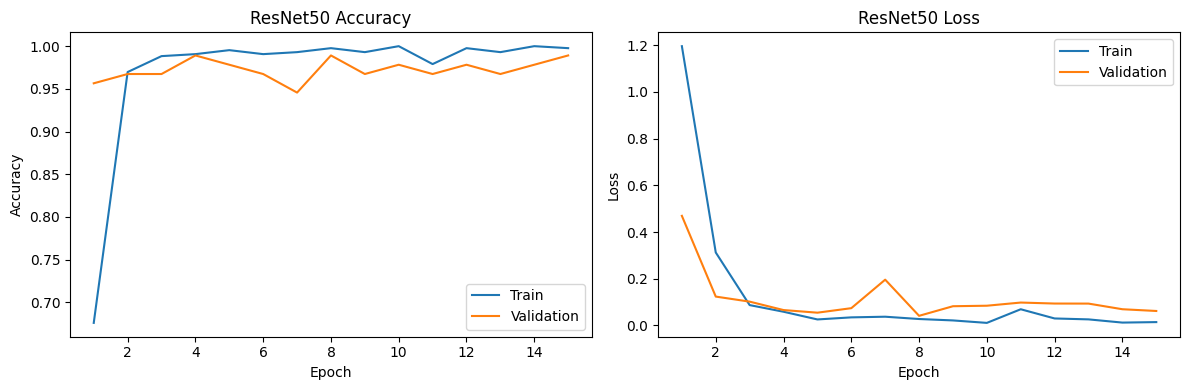

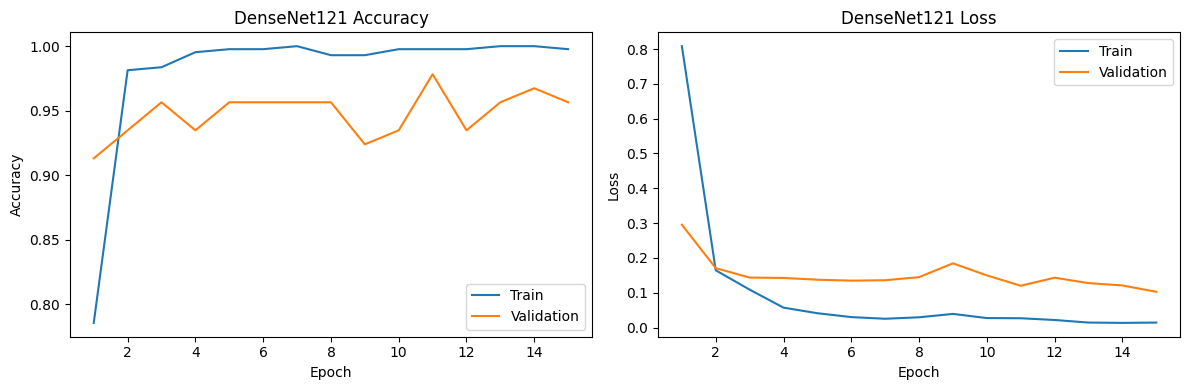

In [ ]:
def plot_history(history, model_name):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history['train_acc'], label='Train')
    axes[0].plot(epochs, history['val_acc'], label='Validation')
    axes[0].set_title(model_name + ' Accuracy')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()
    axes[1].plot(epochs, history['train_loss'], label='Train')
    axes[1].plot(epochs, history['val_loss'], label='Validation')
    axes[1].set_title(model_name + ' Loss')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(resnet_history, 'ResNet50')
plot_history(dense_history, 'DenseNet121')

## 18. Test-set evaluation function

In [ ]:
def evaluate_model(model, model_name):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, targets in test_loader:
            outputs = model(images.to(DEVICE, non_blocking=True))
            y_pred.extend(outputs.argmax(1).cpu().numpy())
            y_true.extend(targets.numpy())

    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1-score': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }
    print(f'\n{model_name} test results')
    for key, value in metrics.items():
        if key != 'Model': print(f'{key}: {value:.4f}')
    print('\nClassification report:')
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
    return y_true, y_pred, metrics

## 19. Evaluate ResNet50 and DenseNet121

In [ ]:
resnet_true, resnet_pred, resnet_metrics = evaluate_model(resnet50, 'ResNet50')
dense_true, dense_pred, dense_metrics = evaluate_model(densenet121, 'DenseNet121')


ResNet50 test results
Accuracy: 0.9891
Precision: 0.9895
Recall: 0.9891
F1-score: 0.9890

Classification report:
              precision    recall  f1-score   support

         cat       1.00      1.00      1.00        15
         cow       1.00      0.93      0.97        15
         dog       1.00      1.00      1.00        15
        lamb       0.97      1.00      0.98        32
       zebra       1.00      1.00      1.00        15

    accuracy                           0.99        92
   macro avg       0.99      0.99      0.99        92
weighted avg       0.99      0.99      0.99        92


DenseNet121 test results
Accuracy: 0.9783
Precision: 0.9783
Recall: 0.9783
F1-score: 0.9783

Classification report:
              precision    recall  f1-score   support

         cat       0.93      0.93      0.93        15
         cow       1.00      1.00      1.00        15
         dog       0.93      0.93      0.93        15
        lamb       1.00      1.00      1.00        32
       ze

## 20. Confusion matrices

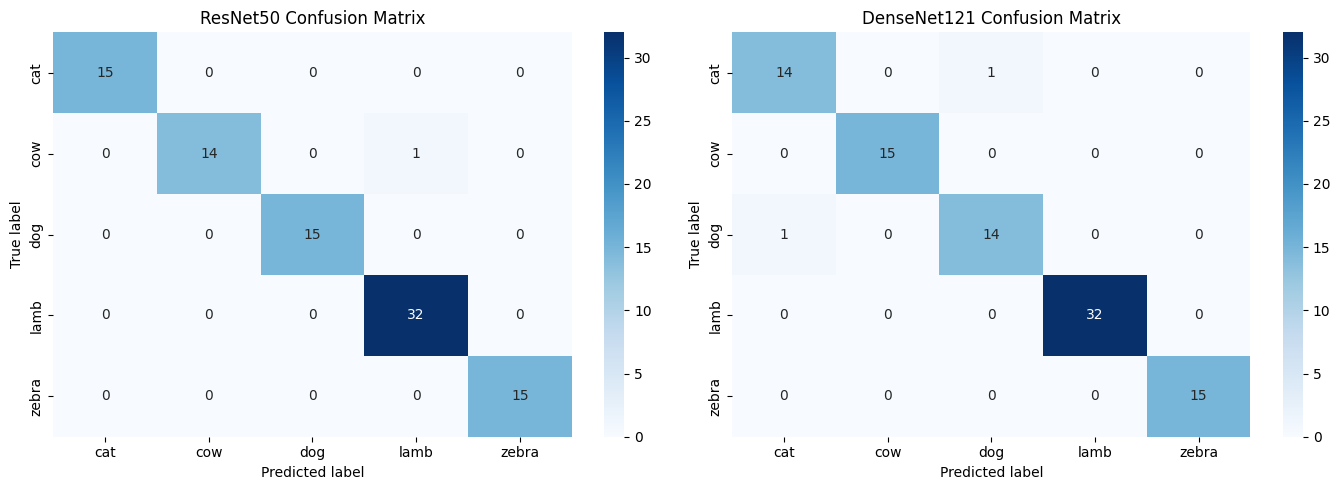

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_true, y_pred, name in [
    (axes[0], resnet_true, resnet_pred, 'ResNet50'),
    (axes[1], dense_true, dense_pred, 'DenseNet121')
]:
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name + ' Confusion Matrix')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
plt.show()

## 21. Compare model performance

,Accuracy,Precision,Recall,F1-score
Model,,,,
ResNet50,0.9891,0.9895,0.9891,0.9890
DenseNet121,0.9783,0.9783,0.9783,0.9783


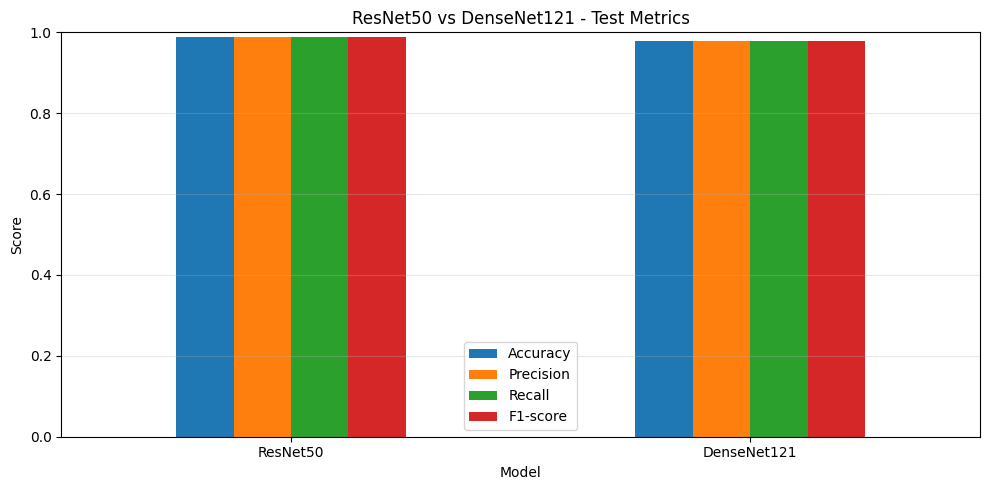

Best model by weighted F1-score: ResNet50


In [ ]:
results = pd.DataFrame([resnet_metrics, dense_metrics]).set_index('Model')
display(results.style.format('{:.4f}'))

results.plot(kind='bar', figsize=(10, 5), ylim=(0, 1))
plt.title('ResNet50 vs DenseNet121 - Test Metrics')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

best_model_name = results['F1-score'].idxmax()
print('Best model by weighted F1-score:', best_model_name)

## 22. Save models and results to Google Drive

In [ ]:
SAVE_DIR = '/content/drive/MyDrive/ResNet50_DenseNet121_Results'
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save(resnet50.state_dict(), os.path.join(SAVE_DIR, 'ResNet50_Final.pth'))
torch.save(densenet121.state_dict(), os.path.join(SAVE_DIR, 'DenseNet121_Final.pth'))
results.to_csv(os.path.join(SAVE_DIR, 'model_comparison.csv'))
with open(os.path.join(SAVE_DIR, 'class_names.txt'), 'w') as f:
    f.write('\n'.join(class_names))

print('Saved all outputs to:', SAVE_DIR)

Saved all outputs to: /content/drive/MyDrive/ResNet50_DenseNet121_Results


## 23. Predict a new image

In [ ]:
def predict_image(image_path, model, model_name):
    image = Image.open(image_path).convert('RGB')
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(tensor), dim=1)[0]
    confidence, index = probabilities.max(dim=0)
    predicted_class = class_names[index.item()]
    print('Model:', model_name)
    print('Predicted class:', predicted_class)
    print(f'Confidence: {confidence.item()*100:.2f}%')
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f'{predicted_class} ({confidence.item()*100:.1f}%)')
    plt.axis('off')
    plt.show()

# Example: replace with the path of a separate image.
# predict_image('/content/my_test_image.jpg', resnet50, 'ResNet50')
# predict_image('/content/my_test_image.jpg', densenet121, 'DenseNet121')